# Customer Churn Prediction

# importing libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest, mutual_info_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
import os

# Load the dataset

In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [4]:
df.tail() 
df.shape 
df.columns 
df.info() 
df.describe() 
df.dtypes 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

# Exploratory Data Analysis (EDA)

# Check missing values

In [5]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
print("Duplicates:", df.duplicated().sum())

print("Customer ID duplicates:",
      df["customerID"].duplicated().sum())

Duplicates: 0
Customer ID duplicates: 0


# Fix TotalCharges

In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].isnull().sum())

11


# Customer churn count

In [8]:
print(df["Churn"].value_counts())

No     5174
Yes    1869
Name: Churn, dtype: int64


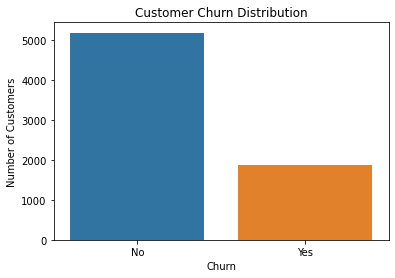

In [9]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

# Calculate churn percentage

In [10]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage)

No     73.463013
Yes    26.536987
Name: Churn, dtype: float64


# Churn by contract type 

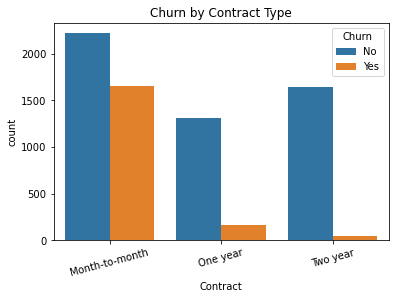

In [11]:
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

# Churn by tenure

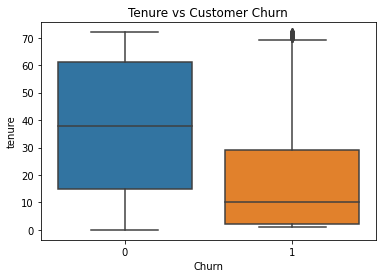

In [53]:
sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Customer Churn")
plt.show()

# Monthly charges

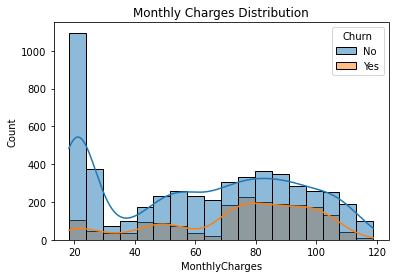

In [12]:
sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    kde=True
)

plt.title("Monthly Charges Distribution")
plt.show()

# Correlation analysis

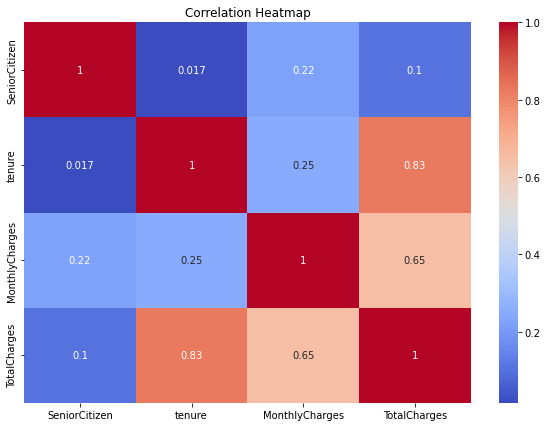

In [13]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
df.drop("customerID", axis=1, inplace=True)

# Convert target into binary values 

In [16]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Separate X and y

In [18]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

# Identify numerical and categorical columns

In [20]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# Train-test split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 19)
Testing: (1409, 19)


# Create preprocessing pipeline

In [22]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Feature selection

In [23]:
feature_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=20
)

# Create models

In [24]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

# Train and evaluate all three models

In [25]:
results = []

best_model = None
best_f1 = 0
best_model_name = ""

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),

        ("feature_selection", SelectKBest(
            score_func=mutual_info_classif,
            k=20
        )),

        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\nModel:", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Churned"],
        zero_division=0
    ))

    if f1 > best_f1:
        best_f1 = f1
        best_model = pipeline
        best_model_name = name

print("Best Model:", best_model_name)


Model: Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.91      0.71      0.80      1035
     Churned       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Model: Decision Tree
              precision    recall  f1-score   support

      Stayed       0.90      0.74      0.81      1035
     Churned       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409


Model: Random Forest
              precision    recall  f1-score   support

      Stayed       0.87      0.79      0.83      1035
     Churned       0.54      0.68      0.60       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
we

# Plot your actual confusion matrix

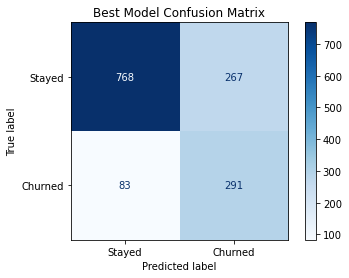

In [48]:
import os
os.makedirs("outputs", exist_ok=True)
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_best
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues")

plt.title("Best Model Confusion Matrix")
plt.savefig("outputs/confusion_matrix.png")
plt.show()

# Compare all models

In [49]:
results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="F1-Score",
    ascending=False
))
results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

                 Model  Accuracy  Precision    Recall  F1-Score
1        Decision Tree  0.751597   0.521505  0.778075  0.624464
0  Logistic Regression  0.735273   0.500835  0.802139  0.616650
2        Random Forest  0.760823   0.538947  0.684492  0.603062


# Save the best machine learning model

In [32]:
joblib.dump(
    best_model,
    "outputs/best_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


# Make predictions for new customers

In [51]:
 # 2. Load aur predict karein
loaded_model = joblib.load("outputs/best_churn_model.pkl")
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 89.50,
    "TotalCharges": 179.00
}])

loaded_model = joblib.load(
    "outputs/best_churn_model.pkl"
)

prediction = loaded_model.predict(new_customer)

probability = loaded_model.predict_proba(
    new_customer
)[0][1]

if prediction[0] == 1:
    print("Customer is likely to CHURN")
else:
    print("Customer is likely to STAY")

print("Churn Probability:", round(probability * 100, 2), "%")

Customer is likely to CHURN
Churn Probability: 87.95 %
